# Unit 6: Membersihkan Data
**Kode unit:** J.62DMI00.008.1 · SKKNI No. 299 Tahun 2020 · Proyek: *Prediksi Arah Harian IHSG*

**Tujuan unit ini:** memperbaiki masalah yang ditemukan di Unit 4.

In [1]:
import json
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

warnings.filterwarnings('ignore')
plt.rcParams['figure.dpi'] = 110

In [2]:
df = pd.read_csv('../data/raw/market_data.csv', parse_dates=['Date'])
minyak_awal = df[['Date', 'OIL']].copy()
print('Jumlah baris awal:', len(df))

Jumlah baris awal: 4365


## Langkah 1 — Hapus baris kosong

In [3]:
df = df.dropna(subset=['IHSG']).reset_index(drop=True)
print('Jumlah baris:', len(df))

Jumlah baris: 4364


## Langkah 2 — Perbaiki harga minyak negatif
Nilai negatif diganti dengan **nilai hari sebelumnya**. Cara ini hanya memakai data masa lalu, sehingga aman.

In [4]:
negatif = df['OIL'] <= 0
df.loc[negatif, 'OIL'] = np.nan
df['OIL'] = df['OIL'].ffill()
print('Harga minyak yang diperbaiki:', negatif.sum())

Harga minyak yang diperbaiki: 1


## Langkah 3 — Hapus hari libur BEI

In [5]:
libur = df['IHSG'].diff() == 0
df = df[~libur].reset_index(drop=True)
print('Hari libur yang dihapus:', libur.sum())
print('Jumlah baris akhir    :', len(df))

Hari libur yang dihapus: 304
Jumlah baris akhir    : 4060


## Pemeriksaan akhir

Data kosong        : 0
Harga ≤ 0          : 0
Hari IHSG tetap    : 0


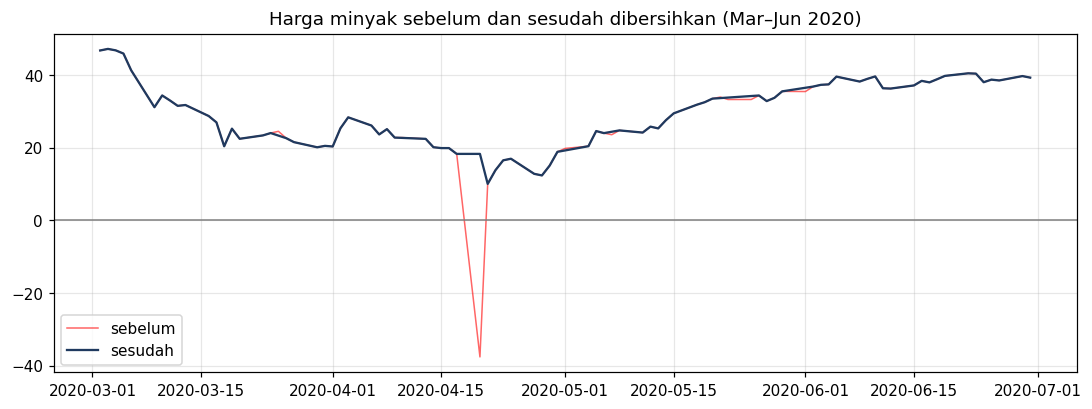

Data bersih disimpan: 4060 baris


In [6]:
print('Data kosong        :', df.isnull().sum().sum())
print('Harga ≤ 0          :', (df[['IHSG', 'SP500', 'OIL', 'GOLD', 'VIX']] <= 0).sum().sum())
print('Hari IHSG tetap    :', (df['IHSG'].diff() == 0).sum())

awal = minyak_awal[(minyak_awal['Date'] >= '2020-03-01') & (minyak_awal['Date'] <= '2020-06-30')]
akhir = df[(df['Date'] >= '2020-03-01') & (df['Date'] <= '2020-06-30')]
plt.figure(figsize=(12, 4))
plt.plot(awal['Date'], awal['OIL'], color='red', linewidth=1, alpha=0.6, label='sebelum')
plt.plot(akhir['Date'], akhir['OIL'], color='#1f3a5f', linewidth=1.5, label='sesudah')
plt.axhline(0, color='grey', linewidth=1)
plt.title('Harga minyak sebelum dan sesudah dibersihkan (Mar–Jun 2020)')
plt.legend()
plt.grid(alpha=0.3)
plt.savefig('../figures/06_minyak_sebelum_sesudah.png', dpi=150, bbox_inches='tight')
plt.show()

df.to_csv('../data/processed/data_bersih.csv', index=False)
print('Data bersih disimpan:', len(df), 'baris')

## Kesimpulan
| Langkah | Hasil |
|---|---|
| Hapus baris kosong | 1 baris |
| Perbaiki harga minyak negatif | 1 nilai |
| Hapus hari libur BEI | 304 baris |

Hasilnya **4.060 hari bursa** tanpa data kosong, disimpan di `data/processed/data_bersih.csv`.